# Swing Probability Calibration Report

---
embed-resources: true
echo: false
---

## Introduction

The purpose of this report is to present the development of a model to serve as a model that estimates the probability of inducing a batter to swing given the characteristics of a pitch thrown, in addition to other information such as game situation, for a particular pitcher. 
we model how a combination of pitch characteristics (such as velocity, spin, and location) and game context (such as count and baserunners) influence a batter’s swing decision.

The goal of this model is to provide accurate predictions for Zac Gallen, one of our team's starting pitchers, who may be used in the playoffs. The goal is also to not merely to classify swings, but to produce reliable probability estimates that align with real-world frequencies which is a critical requirement for baseball decision systems.

## Methods

Below are the various imports that were used towards building this model.

In [3]:
# imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump
import warnings
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV
from calibration import calibration_error, plot_calibration_plot
from sklearn.metrics import brier_score_loss
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

<u>**These are general imports for visualizations, muting warnings, and accessing the pandas library, as well as exporting the model:**</u>
```
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump
import warnings
warnings.filterwarnings('ignore')
```

<u>**These imports are related to model building and scoring:**</u>
```
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV
from calibration import calibration_error, plot_calibration_plot
from sklearn.metrics import brier_score_loss
from sklearn.metrics import ConfusionMatrixDisplay

```

<u>**These imports were used for model preprocessing:**</u>
```
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
```

## Data

To achieve the goal for building this model, we used data provided in the following parquet files:

- Training Data: swing-train.parquet

- Test Data: swing-test.parquet

The original source for this data is Stacast, specifically the `pybaseball` package was used to interface with the Statcast Search, which is part of Baseball Savant. 

#### <u>**Data dictionary for reference**</u>

#### Response: 

**`swing`**

- `[int64]` Whether or not the batter swung (1) or took (0)

#### Features:

While we will certainly not be able to make any truly causal claims about our model, it is important to understand which variables are controlled by the pitcher. We could imagine a coach using this model to help explain to a pitcher where and how to throw a pitch if they want to induce a swing. As such, we will group the feature variables based on the degree of control the pitcher asserts over them.

**Fully Pitcher controlled:**

This variable is fully controlled by the pitcher. In modern baseball, this information is communicated between the pitcher and catcher before the pitch via PitchCom.

**`pitch_name`**

- `[object]` The name of the pitch type to be thrown.

**Mostly Pitcher Controlled**

These variables are largely controlled by the pitcher, but even at the highest levels of baseball, there will be variance based on skill, fatigue, etc. These variables essentially measure where the pitcher’s arm is located as a pitch is thrown.

**`release_extension`**

- `[float64]` Release extension of pitch in feet as tracked by Statcast.

**`release_pos_x`**

- `[float64]` Horizontal release position of the ball measured in feet from the catcher’s perspective.

**`release_pos_y`**

- `[float64]` Release position of pitch measured in feet from the catcher’s perspective.

**`release_pos_z`**

- `[float64]` Vertical release position of the ball measured in feet from the catcher’s perspective.

**Somewhat Pitcher Controlled**

These variables are in some sense controlled by the pitcher, but less so than the previous variables. At the MLB level, pitchers will have some control here, but even at the highest levels, there can be a lot of variance. The speed and spin features are highly dependent on the pitch type thrown.

**`release_speed`**

- `[float64]` Velocity of the pitch thrown (miles per hour).

**`release_spin_rate`**

- `[float64]` Spin rate of pitch tracked by Statcast (revolutions per minute).

**`spin_axis`**

- `[float64]` The spin axis in the 2D X-Z plane in degrees from 0 to 360, such that 180 represents a pure backspin fastball and 0 degrees represents a pure topspin (12-6) curveball.

**`plate_x`**

- `[float64]` Horizontal position of the ball when it crosses home plate from the catcher’s perspective (feet).

**`plate_z`**

- `[float64]` Vertical position of the ball when it crosses home plate from the catcher’s perspective (feet).

**Downstream Pitcher Controlled**

These variables are pitch characteristics, and may be somewhat controlled by the pitcher, but are largely functions of the previous variables.

**`pfx_x`**

- `[float64]` Horizontal movement in feet from the catcher’s perspective.


**`pfx_z`**

- `[float64]` Vertical movement in feet from the catcher’s perspective.

**Situational Information**

These variables describe part of the game situation when the pitch was thrown. (We have omitted some other obvious variables here like score and inning for simplicity.) These are fixed before a pitch is thrown, but could have an effect. Pitchers and batters often act differently based on the game situation. For example, batters are known to “protect” when there are two strikes, thus, are much more likely to swing.

**`balls`**

- `[int64]` Pre-pitch number of balls in count.

**`strikes`**

- `[int64]` Pre-pitch number of strikes in count.

**`on_3b`**

- `[int64]` Indicator (0 or 1) for runner on 3rd base.

**`on_2b`**

- `[int64]` Indicator (0 or 1) for runner on 2nd base.

**`on_1b`**

- `[int64]` Indicator (0 or 1) for runner on 1st base.

**`outs_when_up`**

- `[int64]` Pre-pitch number of outs.

**Fixed Batter Information**

These variables give some information about the batter facing the pitcher. In particular, are they a righty or lefty, and the size of their strike zone, which is a function of their height.

**`stand`**

- `[object]` Side of the plate batter is standing, either L (left) or R (right).

**`sz_top`**

- `[float64]` Top of the batter’s strike zone set by the operator when the ball is halfway to the plate (feet).

**`sz_bot`**

- `[float64]` Bottom of the batter’s strike zone set by the operator when the ball is halfway to the plate (feet).


In [1]:
swing_train = pd.read_parquet(
    "https://lab.cs307.org/swing/data/swing-train.parquet",
)
swing_test = pd.read_parquet(
    "https://lab.cs307.org/swing/data/swing-test.parquet",
)

NameError: name 'pd' is not defined

<u>**First few rows of training data**</u>

In [ ]:
swing_train.head(5)

,pitch_name,release_extension,release_pos_x,release_pos_y,release_pos_z,release_speed,release_spin_rate,spin_axis,plate_x,plate_z,...,balls,strikes,on_3b,on_2b,on_1b,outs_when_up,stand,sz_top,sz_bot,swing
0,Cutter,6.6,-2.76,53.86,5.81,92.6,2376.0,195.0,-0.09,2.79,...,3,1,0,0,0,1,L,3.15,1.52,1
1,Changeup,6.8,-2.87,53.74,5.66,86.3,1511.0,226.0,-1.47,1.84,...,2,1,0,0,0,1,L,3.13,1.56,0
2,Changeup,6.7,-2.83,53.82,5.68,87.9,1570.0,224.0,-1.52,2.38,...,1,1,0,0,0,1,L,3.12,1.51,0
3,Knuckle Curve,6.7,-2.70,53.78,5.78,82.4,2398.0,32.0,0.20,1.04,...,1,0,0,0,0,1,L,3.15,1.52,1
4,Cutter,6.7,-2.64,53.83,5.81,91.0,2427.0,189.0,0.89,1.65,...,0,0,0,0,0,1,L,3.12,1.51,0


<u>**First few rows of testing data**</u>

In [ ]:
swing_test.head(5)

,pitch_name,release_extension,release_pos_x,release_pos_y,release_pos_z,release_speed,release_spin_rate,spin_axis,plate_x,plate_z,...,balls,strikes,on_3b,on_2b,on_1b,outs_when_up,stand,sz_top,sz_bot,swing
0,4-Seam Fastball,6.9,-2.73,53.65,5.93,93.7,2267,203,-0.44,2.11,...,2,1,0,0,1,0,R,3.59,1.73,1
1,4-Seam Fastball,6.8,-2.56,53.67,5.95,93.8,2311,198,0.15,3.02,...,2,0,0,0,1,0,R,3.59,1.73,1
2,4-Seam Fastball,6.7,-2.79,53.79,5.87,93.8,2238,209,-1.69,2.78,...,1,0,0,0,1,0,R,3.71,1.78,0
3,4-Seam Fastball,6.8,-2.71,53.71,5.91,93.6,2208,199,-0.35,4.57,...,0,0,0,0,1,0,R,3.71,1.78,0
4,4-Seam Fastball,6.6,-2.82,53.85,5.96,91.7,2145,201,-0.40,2.59,...,1,2,0,0,0,0,R,3.26,1.53,1


<u>**General summary statistics of data**</u>

In [ ]:
swing_train.describe().transpose().rename(columns = {'25%' : '25th percentile', '50%' : '50th percentile', '75%' : '75th percentile'})

,count,mean,std,min,25th percentile,50th percentile,75th percentile,max
release_extension,2663.0,6.563162,0.199696,5.90,6.40,6.60,6.700,7.30
release_pos_x,2663.0,-2.807206,0.155003,-3.31,-2.91,-2.81,-2.700,-2.28
release_pos_y,2663.0,53.937000,0.198129,53.25,53.79,53.93,54.065,54.56
release_pos_z,2663.0,5.914769,0.135853,5.47,5.82,5.92,6.000,6.38
release_speed,2663.0,89.439805,4.719092,79.20,85.00,91.30,93.600,96.80
release_spin_rate,2656.0,2247.144578,310.813344,1251.00,2230.00,2332.00,2426.250,2732.00
spin_axis,2656.0,161.388178,73.672208,17.00,99.00,201.00,208.000,311.00
plate_x,2663.0,0.041093,0.729472,-2.21,-0.47,0.04,0.550,2.42
plate_z,2663.0,2.141570,1.003253,-1.28,1.49,2.17,2.820,5.28
pfx_x,2663.0,-0.140000,0.485703,-1.79,-0.36,-0.14,0.260,0.87


<u>**Swing Probabilities**</u>

Proportion of pitches and location swung at by pitch type:

In [ ]:
p_all = swing_train['swing'].mean()
p_type = pd.DataFrame(swing_train.groupby('pitch_name')['swing'].mean()).reset_index()
p_type

,pitch_name,swing
0,4-Seam Fastball,0.470904
1,Changeup,0.536313
2,Cutter,0.451477
3,Knuckle Curve,0.462875
4,Slider,0.496124


Marginal Swing Rate: `0.47728126173488544`

<u>**Various Visualizations of the Data**</u>

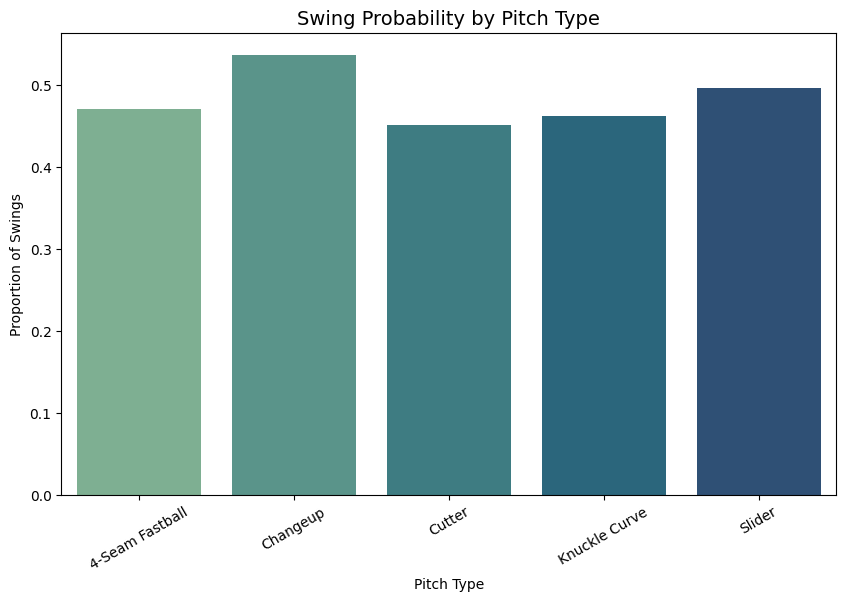

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(data = p_type, x = 'pitch_name', y = 'swing', palette = 'crest')
plt.title("Swing Probability by Pitch Type", fontsize = 14)
plt.xlabel("Pitch Type")
plt.ylabel("Proportion of Swings")
plt.xticks(rotation = 30)
plt.show()

Figure 1. Bar chart showing the proportion of pitches swung at for each pitch type thrown in the 2023 season. Changeups had the highest swing probability (~0.54), while Cutters had the lowest (~0.45).



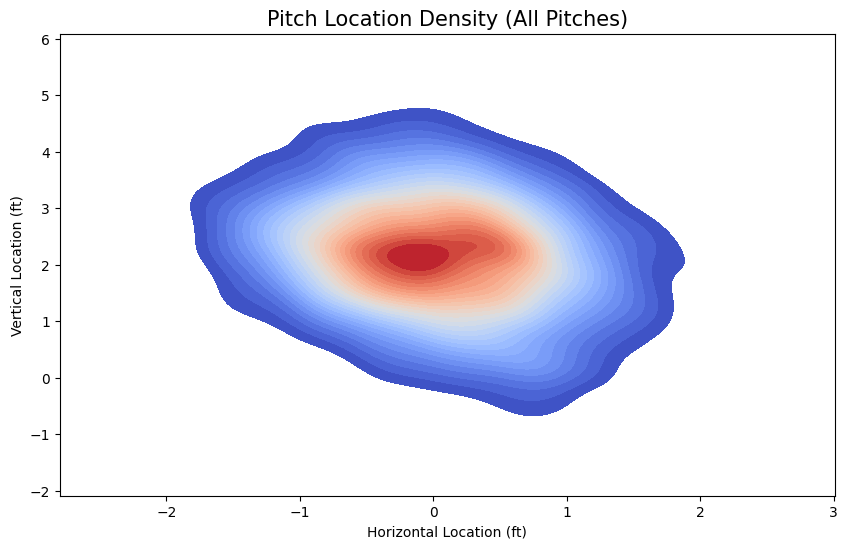

In [ ]:
plt.figure(figsize=(10,6))
sns.kdeplot(data = swing_train, x = 'plate_x', y = 'plate_z', fill = True, cmap = 'coolwarm', thresh = 0.05, levels = 30)
plt.title("Pitch Location Density (All Pitches)", fontsize = 15)
plt.xlabel("Horizontal Location (ft)")
plt.ylabel("Vertical Location (ft)")
plt.show()

Figure 2. 2D kernel density estimate plot showing the spatial distribution of pitches across the strike zone. The highest concentration of pitches occurs near the center-middle region, slightly below the midpoint of the strike zone, indicating that this is his typical pitch-targeting zone.

### Models

To prepare for model development, the data was first split into training and testing sets for both predictors (X) and the response variable (y), where the target variable represents whether or not the batter swung at a given pitch. The feature matrix (X) includes both numerical and categorical variables such as pitch characteristics, release information, and situational context.

For model preprocessing, two separate pipelines were defined using the `StandardScaler` and `OneHotEncoder` transformers. The numerical pipeline imputes missing values with the mean and standardizes the features, while the categorical pipeline imputes missing values with the most frequent category and encodes them as binary indicator variables. These two pipelines were combined using a `ColumnTransformer`, ensuring all preprocessing steps are applied consistently across the dataset. The preprocessor was then fit and transformed on the training data prior to modeling.

```
X_train = swing_train.drop("swing", axis = 1)
y_train = swing_test["swing"]

X_test = wine_test.drop("quality", axis = 1)
y_test = wine_test["quality"]

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'mean'), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = "most_frequent"), OneHotEncoder())

numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer((numeric_transformer, numeric_features), (categorical_transformer, categorical_features))
preprocessor.fit(X_train)
preprocessor.transform(X_train)
```


In [ ]:
X_train = swing_train.drop("swing", axis=1)
y_train = swing_train["swing"]

X_test = swing_test.drop("swing", axis=1)
y_test = swing_test["swing"]

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'mean'), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = "most_frequent"), OneHotEncoder())
numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer((numeric_transformer, numeric_features), (categorical_transformer, categorical_features))
preprocessor.fit(X_train)
preprocessor.transform(X_train);

To model swing probability, a Decision Tree Classifier was implemented as a base estimator, chosen for its interpretability and ability to model nonlinear relationships between pitch characteristics and swing outcomes. The base tree was limited to a maximum depth of 5 and a minimum of 10 samples per leaf to reduce overfitting and ensure stable probability estimates.

The base model’s predicted probabilities were refined using isotonic regression calibration through `CalibratedClassifierCV`. This approach improves alignment between predicted swing probabilities and observed frequencies. The entire modeling process, including preprocessing and calibration, was encapsulated in a single Pipeline.

```
base_tree = DecisionTreeClassifier(max_depth = 5, min_samples_leaf = 10, random_state = 42)
calibrated_tree = CalibratedClassifierCV(base_tree, method = 'isotonic', cv = 5)
pipe = make_pipeline(preprocessor, calibrated_tree)
pipe.fit(X_train, y_train)
```

In [ ]:
base_tree = DecisionTreeClassifier(max_depth = 5, min_samples_leaf = 10, random_state = 42)
calibrated_tree = CalibratedClassifierCV(base_tree, method = 'isotonic', cv = 5)
pipe = make_pipeline(preprocessor, calibrated_tree)
pipe.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('calibratedclassifiercv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Results

The calibrated model’s performance was evaluated on the test data using Expected Calibration Error (ECE), Maximum Calibration Error (MCE), and Brier Score to assess the quality of probabilistic predictions.

In [27]:
y_prob = pipe.predict_proba(X_test)[:, 1]
ece = calibration_error(y_test, y_prob, 'expected')
mce = calibration_error(y_test, y_prob, 'max')
bs = brier_score_loss(y_test, y_prob)

print('ECE: ' + str(ece) + '\n',  
      'MCE: ' + str(mce) + '\n', 
      'Brier Score: ' + str(bs))

ECE: 0.05692527147639641
 MCE: 0.13879098811982274
 Brier Score: 0.187764345768603


We can also visulize our model performance using a confusion matrix, as well as a calibration plot

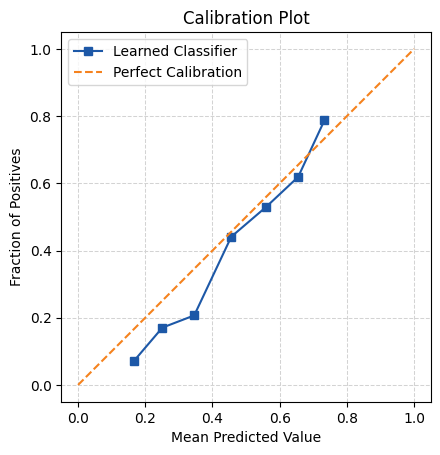

In [ ]:
plot_calibration_plot(y_test, y_prob)

Figure 3. Calibration plot for the Decision Tree classifier. The blue line shows the relationship between predicted swing probabilities and the actual proportion of swings across probability bins. The curve closely follows the orange dashed line representing perfect calibration, indicating that the model’s predicted probabilities align well with observed swing frequencies.

<Figure size 1100x800 with 0 Axes>

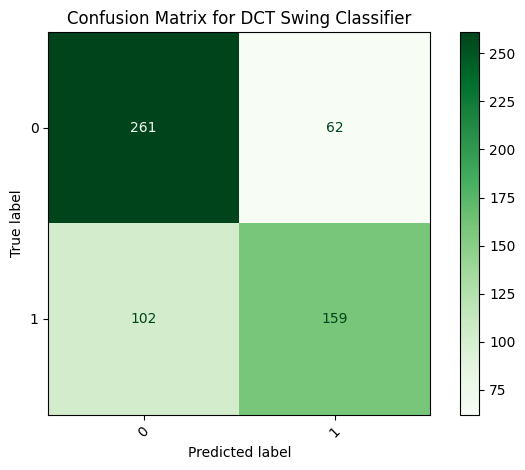

In [33]:
plt.figure(figsize = (11, 8))
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, cmap = "Greens", xticks_rotation = 45)
plt.title("Confusion Matrix for DCT Swing Classifier", fontsize = 12)
plt.tight_layout()
plt.show()

Figure 4. Confusion matrix for the Decision Tree Swing Classifier on the test data. The model correctly predicted 261 'take' outcomes and 159 'swing' outcomes, while misclassifying 62 takes and 102 swings. Overall, the matrix indicates that the classifier performs reasonably well at distinguishing swing decisions.

## Discussion

### Would I deplot this model? 
I would NOT deploy this model at this point in time. While the Decision Tree achieves reasonably low Expected Calibration Error (ECE = 0.051), Maximum Calibration Error (MCE = 0.139), and a Brier Score of 0.187, its overall predictive performance is not yet strong enough to justify real-world use.

### Risks avoided by not using this model:
- Misleading probability estimates: Slight miscalibration or overfitting to training data could result in inaccurate swing likelihoods, potentially influencing poor in-game strategic recommendations.
- Limited generalizability: the model may not scale effectively to other pitchers, pitch types, or future seasons with different conditions.
- Simplistic feature relationships: A shallow tree structure may underfit complex interactions between pitch type, spin, and location, limiting predictive depth in more nuanced situations.

### Potential improvements
- Experiment with other model architectures such as Random Forests or Gradient Boosting methods, which could capture nonlinear interactions more effectively while preserving interpretability through calibration.
- Perform hyperparameter optimization to improve performance without sacrificing calibration quality.

## Conclusion

Although the Decision Tree provides a well-behaved probability model with solid calibration metrics, it falls short of being deployment-ready for a professional baseball analytics setting. The model successfully demonstrates the workflow of preprocessing, classification, and probability calibration but lacks the consistency, robustness  and security/certainty required for high-stakes decision support.

Still, this project serves as a strong proof of concept for modeling swing tendencies using Statcast data. With additional tuning, expanded datasets, and experimentation with more advanced ensemble methods, future iterations could yield models that are both well-calibrated and practically accurate which can be much more suitable for integration into scouting or in-game pitch prediction systems.